# SMS Spam Classifier

Building a text classifier that flags spam SMS messages. The tricky part isn't getting high accuracy (87% of
messages are legitimate, so "nothing is spam" is already 87% accurate). It's **not blocking real messages**:
a missed spam is annoying, but a friend's message disappearing into a spam folder is worse.

Dataset: UCI SMS Spam Collection (5,572 messages in English, 13% spam).

Steps:
1. EDA: what makes spam look different
2. Text preprocessing and TF-IDF features (word and character n-grams)
3. Compare Naive Bayes, Logistic Regression and Linear SVM with cross-validation
4. Tune for precision, evaluate on a test set and read through the mistakes
5. Package the model with a small command-line script (`predict.py`)

In [1]:
import json
import re
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.calibration import CalibratedClassifierCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, classification_report, confusion_matrix, f1_score,
                             precision_recall_curve, precision_score, recall_score)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict, cross_validate, train_test_split
from sklearn.naive_bayes import MultinomialNB, ComplementNB
from sklearn.pipeline import FeatureUnion, Pipeline
from sklearn.svm import LinearSVC

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
IMG = Path("images"); IMG.mkdir(exist_ok=True)
Path("models").mkdir(exist_ok=True)
SEED = 42

## 1. Load and explore

In [2]:
df = pd.read_csv("data/sms_spam.tsv", sep="\t", header=None, names=["label", "text"])
df["spam"] = (df["label"] == "spam").astype(int)
print(df.shape, "| duplicates:", df.duplicated("text").sum())
print(df["label"].value_counts(normalize=True).round(3).to_dict())
df.sample(5, random_state=1)

(5572, 3) | duplicates: 403
{'ham': 0.866, 'spam': 0.134}


,label,text,spam
1078,ham,"Yep, by the pretty sculpture",0
4028,ham,"Yes, princess. Are you going to make me moan?",0
958,ham,Welp apparently he retired,0
4642,ham,Havent.,0
4674,ham,I forgot 2 ask ü all smth.. There's a card on ...,0


There are ~400 exact duplicate messages (mostly repeated spam campaigns and common replies like "Ok lar...").
If the same message ends up in both train and test, the test score gets inflated, so I drop duplicates
**before** splitting.

In [3]:
df = df.drop_duplicates("text").reset_index(drop=True)
df["length"] = df["text"].str.len()
df["n_digits"] = df["text"].str.count(r"\d")
df["has_url"] = df["text"].str.contains(r"http|www\.|\.com", case=False).astype(int)
df["has_currency"] = df["text"].str.contains(r"£|\$|€|\bp\b|pence", case=False).astype(int)
df["upper_ratio"] = df["text"].apply(lambda t: sum(c.isupper() for c in t) / max(len(t), 1))
print(len(df), "unique messages,", df["spam"].sum(), "spam")
df.groupby("label")[["length", "n_digits", "has_url", "has_currency", "upper_ratio"]].mean().round(3)

5169 unique messages, 653 spam


,length,n_digits,has_url,has_currency,upper_ratio
label,,,,,
ham,70.906,0.297,0.003,0.006,0.057
spam,137.704,15.489,0.161,0.338,0.110


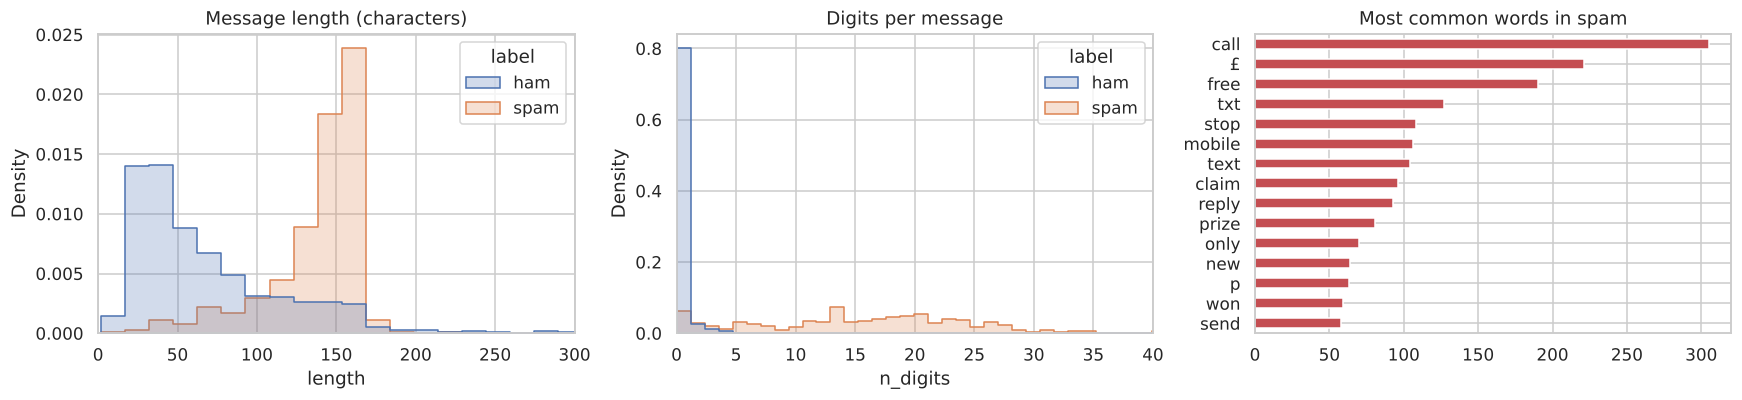

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
sns.histplot(data=df, x="length", hue="label", bins=60, stat="density", common_norm=False, element="step", ax=axes[0])
axes[0].set(xlim=(0, 300), title="Message length (characters)")
sns.histplot(data=df, x="n_digits", hue="label", bins=40, stat="density", common_norm=False, element="step", ax=axes[1])
axes[1].set(xlim=(0, 40), title="Digits per message")
words = lambda s: pd.Series(" ".join(s).lower().split()).str.replace(r"[^a-z£]", "", regex=True)
stop = {"", "to", "a", "you", "the", "your", "for", "is", "and", "or", "of", "in", "on", "i", "u", "me", "my", "it",
        "now", "be", "are", "have", "with", "this", "that", "will", "from", "at", "we", "so", "can", "not", "get", "but",
        "do", "if", "just", "all", "no", "our", "an", "by", "ur"}
top_spam = words(df.loc[df.spam == 1, "text"]); top_spam = top_spam[~top_spam.isin(stop)].value_counts().head(15)
top_spam.iloc[::-1].plot.barh(ax=axes[2], color="#C44E52"); axes[2].set_title("Most common words in spam")
plt.tight_layout(); plt.savefig(IMG / "eda.png", bbox_inches="tight"); plt.show()

Spam is longer (it fills the 160-character limit), packed with digits (phone numbers, shortcodes, prize amounts),
and uses words like *free, call, txt, claim, prize, mobile*. Character n-grams should pick up patterns like
shortcodes and "£1000" that plain word tokens miss.

## 2. Features and model comparison

Two TF-IDF views of each message, combined:
- **word unigrams + bigrams**, e.g. "free", "call now"
- **character 2-5 grams** within word boundaries, which catch odd spellings ("FR33"), numbers and shortcodes

In [5]:
def normalise(t):
    t = t.lower()
    t = re.sub(r"https?://\S+|www\.\S+", " URL ", t)
    t = re.sub(r"£\s?\d+|\$\s?\d+|\d+\s?p\b", " MONEY ", t)
    t = re.sub(r"\b\d{5,}\b", " LONGNUM ", t)     # phone numbers, shortcodes
    return t

def features():
    return FeatureUnion([
        ("word", TfidfVectorizer(preprocessor=normalise, ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
        ("char", TfidfVectorizer(preprocessor=normalise, analyzer="char_wb", ngram_range=(2, 5), min_df=3, sublinear_tf=True)),
    ])

X_train, X_test, y_train, y_test = train_test_split(df["text"], df["spam"], test_size=0.2, stratify=df["spam"], random_state=SEED)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
models = {
    "Multinomial NB": MultinomialNB(alpha=0.05),
    "Complement NB": ComplementNB(alpha=0.3),
    "Logistic Regression": LogisticRegression(C=20, max_iter=3000, class_weight="balanced"),
    "Linear SVM": LinearSVC(C=0.5, class_weight="balanced"),
}
rows = []
for name, m in models.items():
    s = cross_validate(Pipeline([("tfidf", features()), ("clf", m)]), X_train, y_train, cv=cv,
                       scoring=["precision", "recall", "f1", "accuracy"])
    rows.append({"model": name, **{k.replace("test_", ""): v.mean() for k, v in s.items() if k.startswith("test_")}})
cv_table = pd.DataFrame(rows).sort_values("f1", ascending=False).reset_index(drop=True)
cv_table.round(4)

,model,precision,recall,f1,accuracy
0,Linear SVM,0.9863,0.9482,0.9668,0.9918
1,Logistic Regression,0.9842,0.9463,0.9648,0.9913
2,Multinomial NB,0.9596,0.9482,0.9538,0.9884
3,Complement NB,0.9414,0.9482,0.9447,0.9860


All four are strong (F1 0.94-0.97), which is typical for this dataset since spam vocabulary is very distinctive.
**Linear SVM** comes out on top, and logistic regression is right behind it. The Naive Bayes models have the
same recall but noticeably lower precision, meaning they block more real messages.

## 3. Tuning the best model

In [6]:
best_name = cv_table.loc[0, "model"]
print("Tuning:", best_name)
pipe = Pipeline([("tfidf", features()), ("clf", models[best_name])])
grids = {
    "Linear SVM": {"clf__C": [0.1, 0.3, 0.5, 1, 2]},
    "Logistic Regression": {"clf__C": [3, 10, 20, 50, 100]},
    "Multinomial NB": {"clf__alpha": [0.01, 0.03, 0.05, 0.1, 0.3]},
    "Complement NB": {"clf__alpha": [0.05, 0.1, 0.3, 0.5, 1.0]},
}
grid = GridSearchCV(pipe, {**grids[best_name], "tfidf__word__ngram_range": [(1, 1), (1, 2)]}, scoring="f1", cv=cv, n_jobs=1)
grid.fit(X_train, y_train)
print("Best params:", grid.best_params_, "| CV F1: {:.4f}".format(grid.best_score_))

Tuning: Linear SVM


Best params: {'clf__C': 0.3, 'tfidf__word__ngram_range': (1, 1)} | CV F1: 0.9668


## 4. Setting the threshold for high precision

I'd rather let a little spam through than block real messages. So instead of the default decision boundary,
I pick the threshold that keeps **precision at or above 99%** on out-of-fold predictions, and take the best
recall possible under that constraint. Calibrating the model first turns SVM margins into probabilities.

In [7]:
calibrated = CalibratedClassifierCV(grid.best_estimator_, method="sigmoid", cv=5)
oof = cross_val_predict(calibrated, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof)
ok = np.where(prec[:-1] >= 0.99)[0]
threshold = float(thr[ok[np.argmax(rec[ok])]]) if len(ok) else 0.5
print(f"Threshold for >=99% precision: {threshold:.3f} (out-of-fold recall at that point: {rec[ok[np.argmax(rec[ok])]]:.3f})")

Threshold for >=99% precision: 0.649 (out-of-fold recall at that point: 0.921)


## 5. Test set evaluation

In [8]:
calibrated.fit(X_train, y_train)
proba = calibrated.predict_proba(X_test)[:, 1]
pred = (proba >= threshold).astype(int)
pred_default = (proba >= 0.5).astype(int)
print(classification_report(y_test, pred, target_names=["ham", "spam"], digits=3))
summary = pd.DataFrame({
    "threshold": [0.5, threshold],
    "precision": [precision_score(y_test, pred_default), precision_score(y_test, pred)],
    "recall": [recall_score(y_test, pred_default), recall_score(y_test, pred)],
    "f1": [f1_score(y_test, pred_default), f1_score(y_test, pred)],
    "real messages blocked": [int(((pred_default == 1) & (y_test == 0)).sum()), int(((pred == 1) & (y_test == 0)).sum())],
    "spam missed": [int(((pred_default == 0) & (y_test == 1)).sum()), int(((pred == 0) & (y_test == 1)).sum())],
}, index=["default (0.5)", "high-precision"])
summary.round(3)

              precision    recall  f1-score   support

         ham      0.991     0.998     0.994       903
        spam      0.984     0.939     0.961       131

    accuracy                          0.990      1034
   macro avg      0.988     0.968     0.978      1034
weighted avg      0.990     0.990     0.990      1034



,threshold,precision,recall,f1,real messages blocked,spam missed
default (0.5),0.500,0.977,0.954,0.965,3,6
high-precision,0.649,0.984,0.939,0.961,2,8


The higher threshold blocks one fewer real message at the cost of letting two more spam messages through. On
1,034 test messages the model makes **10 mistakes in total**: 2 real messages blocked and 8 spam missed, with
98.4% precision and 93.9% recall on spam.

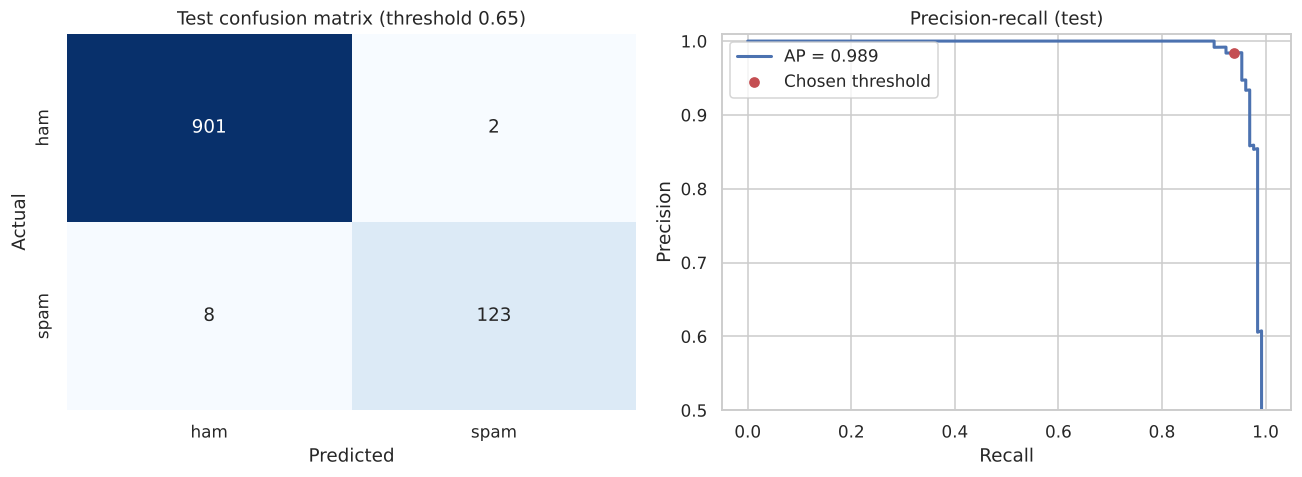

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
cm = confusion_matrix(y_test, pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=["ham", "spam"], yticklabels=["ham", "spam"])
axes[0].set(xlabel="Predicted", ylabel="Actual", title=f"Test confusion matrix (threshold {threshold:.2f})")
p, r, _ = precision_recall_curve(y_test, proba)
axes[1].plot(r, p, lw=2, label=f"AP = {average_precision_score(y_test, proba):.3f}")
axes[1].scatter([recall_score(y_test, pred)], [precision_score(y_test, pred)], color="#C44E52", zorder=5, label="Chosen threshold")
axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision-recall (test)", ylim=(0.5, 1.01)); axes[1].legend()
plt.tight_layout(); plt.savefig(IMG / "evaluation.png", bbox_inches="tight"); plt.show()

## 6. What the model learned

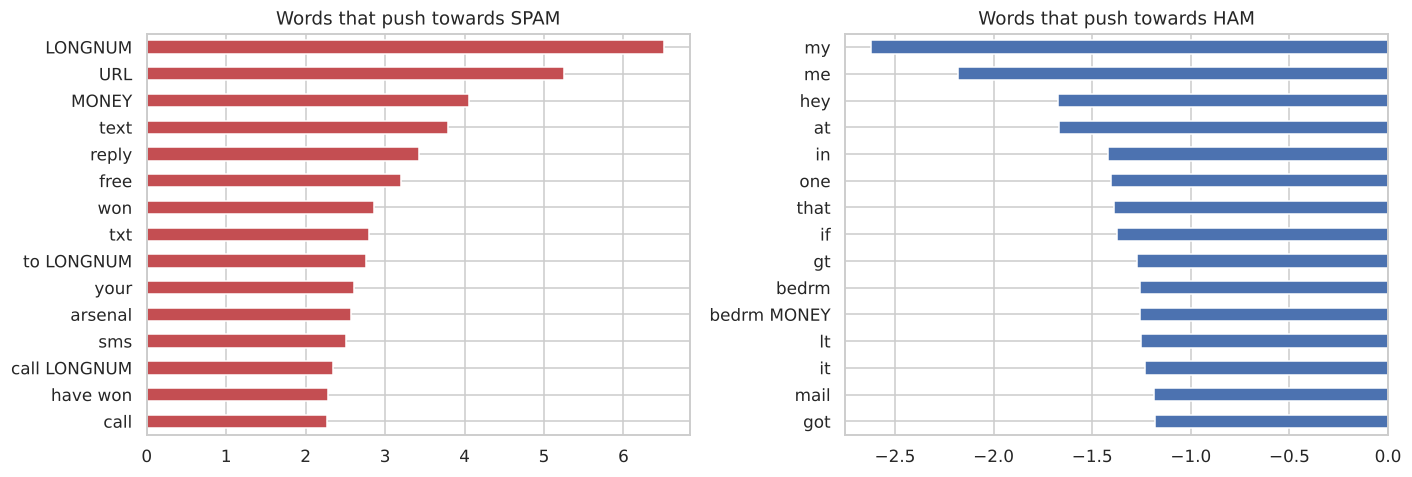

In [10]:
lr = Pipeline([("tfidf", features()), ("clf", LogisticRegression(C=20, max_iter=3000, class_weight="balanced"))]).fit(X_train, y_train)
names = np.array([n.split("__", 1)[1] for n in lr.named_steps["tfidf"].get_feature_names_out()])
coef = lr.named_steps["clf"].coef_[0]
word_mask = np.array([n.startswith("word__") for n in lr.named_steps["tfidf"].get_feature_names_out()])
order = np.argsort(coef[word_mask])
w_names, w_coef = names[word_mask], coef[word_mask]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
pd.Series(w_coef[order[-15:]], index=w_names[order[-15:]]).plot.barh(ax=axes[0], color="#C44E52")
axes[0].set_title("Words that push towards SPAM")
pd.Series(w_coef[order[:15]], index=w_names[order[:15]]).iloc[::-1].plot.barh(ax=axes[1], color="#4C72B0")
axes[1].set_title("Words that push towards HAM")
plt.tight_layout(); plt.savefig(IMG / "top_words.png", bbox_inches="tight"); plt.show()

(These come from a logistic regression trained on the same features, since its coefficients are easy to read.)

## 7. Error analysis

Reading the actual mistakes is the most useful step for knowing what to fix next.

In [11]:
errors = pd.DataFrame({"text": X_test, "actual": y_test.map({0: "ham", 1: "spam"}), "p_spam": proba.round(3)})
fp = errors[(pred == 1) & (y_test == 0)]
fn = errors[(pred == 0) & (y_test == 1)].sort_values("p_spam")
EXPLICIT = re.compile(r"\b(xxx|sexy|bitch|nasty|filthy\w*|rude|hard|slo)\b", re.I)
mask = lambda t: EXPLICIT.sub("***", t)   # some spam in this dataset is explicit; masked for readability
print(f"Real messages flagged as spam: {len(fp)}")
for _, r in fp.iterrows(): print(f"  [{r.p_spam:.2f}] {mask(r.text[:140])}")
print(f"\nSpam that got through: {len(fn)}")
for _, r in fn.iterrows(): print(f"  [{r.p_spam:.2f}] {mask(r.text[:140])}")

Real messages flagged as spam: 2
  [0.78] Glad to see your reply.
  [0.72] I (Career Tel) have added u as a contact on INDYAROCKS.COM to send FREE SMS. To remove from phonebook - sms NO to  &lt;#&gt;

Spam that got through: 8
  [0.01] In The Simpsons Movie released in July 2007 name the band that died at the start of the film? A-Green Day, B-Blue Day, C-Red Day. (Send A, B
  [0.02] Would you like to see my *** pics they are so hot they were nearly banned in the uk!
  [0.09] Burger King - Wanna play footy at a top stadium? Get 2 Burger King before 1st Sept and go Large or Super with Coca-Cola and walk out a winne
  [0.11] Latest News! Police station toilet stolen, cops have nothing to go on!
  [0.19] Babe: U want me dont u baby! Im *** and have a thing 4 ***. Fancy a *** time with a *** ***. How about we go *** n ***! Txt XX
  [0.30] Xmas & New Years Eve tickets are now on sale from the club, during the day from 10am till 8pm, and on Thurs, Fri & Sat night this week. They
  [0.57] Bough

Looking through these:
- Of the two "real" messages that got blocked, one ("I (Career Tel) have added u as a contact on INDYAROCKS.COM
  to send FREE SMS...") is honestly promotional spam that was labelled as ham. Some test "errors" are
  **labelling mistakes** in the dataset.
- The other ("Glad to see your reply.") is a real false positive, probably because short, generic phrases like
  this also show up in spam conversation-starters.
- Most missed spam is **unusual spam**: a quiz question, a Burger King promotion, a joke, a complaint about
  ringtone charges. These don't use the usual "FREE / call now / £1000" vocabulary, so a bag-of-words model has
  little to go on.

**What would help next:** a small transformer model (e.g. DistilBERT) to capture meaning beyond keywords, plus
features like "contains a premium shortcode" that don't depend on wording.

## 8. Save the model

In [12]:
joblib.dump({"model": calibrated, "threshold": threshold}, "models/spam_model.joblib")
hp = summary.loc["high-precision"]
results = {
    "n_messages_unique": int(len(df)), "cv": cv_table.round(4).to_dict(orient="records"),
    "best_model": best_name, "best_params": {k: str(v) for k, v in grid.best_params_.items()},
    "threshold": round(threshold, 3), "test_precision": round(float(hp["precision"]), 4),
    "test_recall": round(float(hp["recall"]), 4), "test_f1": round(float(hp["f1"]), 4),
    "test_ap": round(float(average_precision_score(y_test, proba)), 4),
    "ham_blocked": int(hp["real messages blocked"]), "spam_missed": int(hp["spam missed"]),
    "n_test": int(len(y_test)), "n_test_spam": int(y_test.sum()),
}
Path("results").mkdir(exist_ok=True)
json.dump(results, open("results/metrics.json", "w"), indent=2)
results

{'n_messages_unique': 5169,
 'cv': [{'model': 'Linear SVM',
   'precision': 0.9863,
   'recall': 0.9482,
   'f1': 0.9668,
   'accuracy': 0.9918},
  {'model': 'Logistic Regression',
   'precision': 0.9842,
   'recall': 0.9463,
   'f1': 0.9648,
   'accuracy': 0.9913},
  {'model': 'Multinomial NB',
   'precision': 0.9596,
   'recall': 0.9482,
   'f1': 0.9538,
   'accuracy': 0.9884},
  {'model': 'Complement NB',
   'precision': 0.9414,
   'recall': 0.9482,
   'f1': 0.9447,
   'accuracy': 0.986}],
 'best_model': 'Linear SVM',
 'best_params': {'clf__C': '0.3', 'tfidf__word__ngram_range': '(1, 1)'},
 'threshold': 0.649,
 'test_precision': 0.984,
 'test_recall': 0.9389,
 'test_f1': 0.9609,
 'test_ap': 0.9888,
 'ham_blocked': 2,
 'spam_missed': 8,
 'n_test': 1034,
 'n_test_spam': 131}